# Industry Classification Using Business Description Embeddings and Financial Data

Logistic regression and k-NN classify the supplied embeddings. A soft-voting ensemble
uses held-out calibration data to estimate correctness confidence with financial evidence.
Place `df_train.pkl` and `df_financials_train.pkl` in `data/` beside this notebook.
Numbered code comments refer to the separate `project_explanation.pdf`.

## Imports and resources



In [1]:
import ast  # [01.01] Parse embedding strings safely as literal values.
from time import perf_counter  # [01.02] Measure elapsed time with a monotonic clock.
import numpy as np  # [01.03] Use numerical arrays and vector operations.
import pandas as pd  # [01.04] Load and join labeled tables.
import matplotlib.pyplot as plt  # [01.05] Create figures and label their axes.
import seaborn as sns  # [01.06] Draw the scatterplot, heatmaps, and boxplots.
from IPython.display import display  # [01.07] Display readable tables in Jupyter.
from sklearn.decomposition import PCA  # [01.08] Import the PCA implementation.
# [01.09] Use the same established estimator for industry and correctness models.
from sklearn.linear_model import LogisticRegression
# [01.10] Import the required classification and scoring tools.
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit  # [01.11] Split company groups without separating repeated IDs.
from sklearn.neighbors import KNeighborsClassifier  # [01.12] Import the neighbor classifier.
from sklearn.preprocessing import LabelEncoder  # [01.13] Map industry names to integer class codes.
from threadpoolctl import threadpool_limits  # [01.14] Control numerical-library CPU threads.
threadpool_limits(2)  # [01.15] Limit numerical-library threads to two.
started = perf_counter()  # [01.16] Start timing after imports and thread setup.

## Loading Data

Financial records are joined by company ID. Within-company medians resolve repeated financial rows;
infinities become missing, and valid negative values remain. A left join retains companies without finances.

In [2]:
# [02.01] Select the three supplied numerical financial ratios.
ratios = ['net_profit_margin', 'ebitda_margin', 'asset_turnover']
financials = pd.read_pickle('data/df_financials_train.pkl')  # [02.02] Read the supplied financial table.
# [02.03] Count missing and infinite values before cleaning.
display(pd.DataFrame({'Missing': financials[ratios].isna().sum(), 'Infinite': np.isinf(financials[ratios]).sum()}))
# [02.04] Check how many financial rows repeat a company ID.
print('Repeated financial IDs:', financials.id.duplicated().sum())
# [02.05] Treat infinity as missing; take one median per ratio and company.
financials = financials.replace([np.inf, -np.inf], np.nan).groupby('id')[ratios].median()
# [02.06] Keep every main record and attach at most one financial row per ID.
df = pd.read_pickle('data/df_train.pkl').merge(financials, on='id', how='left', validate='many_to_one')

,Missing,Infinite
net_profit_margin,1111,2131
ebitda_margin,19279,824
asset_turnover,1363,5


Repeated financial IDs: 162


## Separating the companies

Company IDs stay together: approximately 81% fitting, 4.5% tuning, 4.5% confidence calibration,
and 10% final validation. Only fitting records teach PCA, the classifiers, and financial profiles.
Tuning selects the voting weight; calibration learns confidence.

In [3]:
def split(companies, size):  # [03.01] Reuse one short company-group splitting function.
    # [03.02] Choose one reproducible group split of the requested size.
    splitter = GroupShuffleSplit(n_splits=1, test_size=size, random_state=42)
    left, right = next(splitter.split(companies, groups=companies.id))  # [03.03] Take its two arrays of row positions.
    return companies.iloc[left], companies.iloc[right]  # [03.04] Select those rows without changing their order.

df_development, df_val = split(df, 0.1)  # [03.05] Reserve about ten percent of company IDs for validation.
df_fit, df_other = split(df_development, 0.1)  # [03.06] Separate model fitting from the remaining development records.
df_tune, df_cal = split(df_other, 0.5)  # [03.07] Divide the held-out development records into tuning and calibration.
parts = [df_fit, df_tune, df_cal, df_val]  # [03.08] Keep one consistent order for all feature and label sets.

def embeddings(companies):  # [03.09] Reuse the embedding conversion for existing and new companies.
    # [03.10] Parse the strings and store their coordinates as float32 arrays.
    return np.array(companies.business_description_embedding.apply(ast.literal_eval).tolist(), dtype=np.float32)

X_fit, X_tune, X_cal, X_val = [embeddings(part) for part in parts]  # [03.11] Convert each of the four sets once.
# [03.12] Show the actual record counts rather than assumed percentages.
print('Fitting, tuning, calibration, validation records:', [len(part) for part in parts])
print('Embedding coordinates:', X_fit.shape[1])  # [03.13] Show how many coordinates each embedding contains.

Fitting, tuning, calibration, validation records: [25681, 1427, 1427, 3171]
Embedding coordinates: 768


## Transforming Data (Label Encoding) and class distribution



In [4]:
le = LabelEncoder().fit(df_fit.industry)  # [04.01] Learn the industry-code mapping from fitting records only.
# [04.02] Check the skeleton requirement that held-out classes are known.
assert set(df_tune.industry).union(df_cal.industry, df_val.industry).issubset(le.classes_)
# [04.03] Apply the same mapping to every target vector.
y_fit, y_tune, y_cal, y_val = [le.transform(part.industry) for part in parts]
counts = df_fit.industry.value_counts()  # [04.04] Count industries in the actual classifier-fitting set.
# [04.05] Show counts and proportions without an additional plot.
display(pd.DataFrame({'Fitting records': counts, 'Share': counts / counts.sum()}))

,Fitting records,Share
industry,,
Materials,6797,0.264670
Capital Goods,2516,0.097971
"Pharmaceuticals, Biotechnology & Life Sciences",1563,0.060862
Financial Services,1557,0.060628
Technology Hardware & Equipment,1237,0.048168
Software & Services,1220,0.047506
Energy,1071,0.041704
Consumer Durables & Apparel,921,0.035863
"Food, Beverage & Tobacco",904,0.035201


Materials has 6,797 fitting records (26.5%); Consumer Staples Distribution & Retail has 151 — about a 45-fold difference. These are the actual classifier-fitting counts, rather than counts from the broader development pool.

## PCA — dimensionality reduction and visualization

PCA is fitted only on fitting embeddings. The first two coordinates give the required scatterplot;
k-NN uses all 128 retained coordinates. Logistic regression keeps the original 768 coordinates.

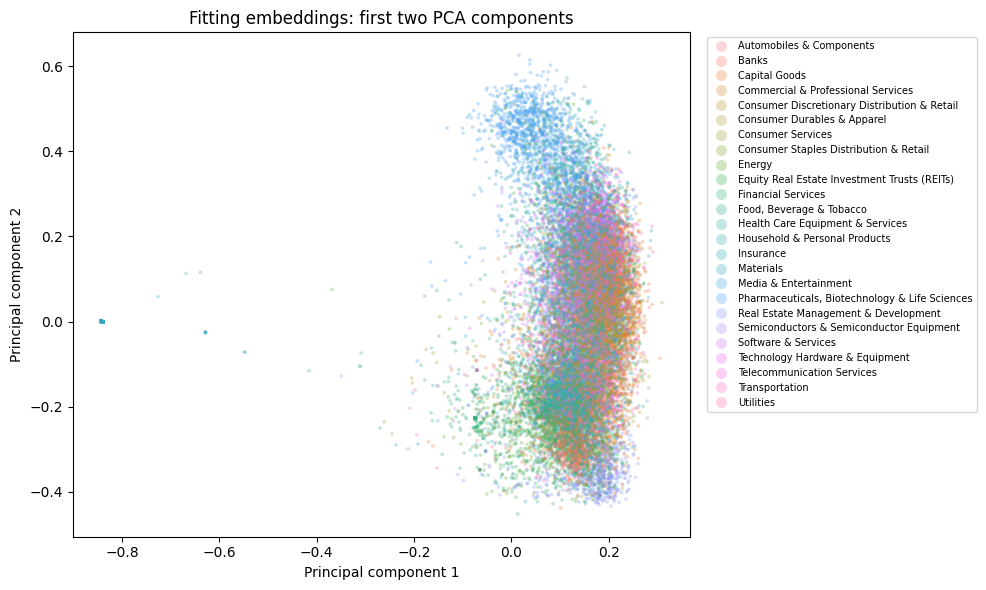

Variance retained by 2 and 128 components: 0.25287107 0.8762428


In [5]:
fit_started = perf_counter()  # [05.01] Start timing PCA preparation.
pca = PCA(n_components=128, random_state=42)  # [05.02] Keep 128 components using the fixed random seed.
P_fit = pca.fit_transform(X_fit)  # [05.03] Learn PCA from fitting embeddings and project them.
# [05.04] Project the other sets without learning another PCA.
P_tune, P_cal, P_val = [pca.transform(X) for X in [X_tune, X_cal, X_val]]
fit_seconds = perf_counter() - fit_started  # [05.05] Store the PCA and transformation time.
fig, ax = plt.subplots(figsize=(10, 6))  # [05.06] Create a figure and axes for the required scatterplot.
# [05.07] Color fitting points by industry; small transparent points show overlap.
sns.scatterplot(x=P_fit[:, 0], y=P_fit[:, 1], hue=df_fit.industry.to_numpy(),
                hue_order=le.classes_, palette='husl', s=7, alpha=0.3, linewidth=0, ax=ax)
ax.set(xlabel='Principal component 1', ylabel='Principal component 2',  # [05.08] Label the two PCA coordinates and the plot.
       title='Fitting embeddings: first two PCA components')
# [05.09] Place the long industry legend outside the data region.
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7, markerscale=3)
fig.tight_layout()  # [05.10] Fit the labels and legend within the figure.
plt.show()  # [05.11] Display the scatterplot.
# [05.12] Report the fractions of variance retained, not classification accuracy.
print('Variance retained by 2 and 128 components:',
      pca.explained_variance_ratio_[:2].sum(), pca.explained_variance_ratio_.sum())

The first two components retain 25.3% of variance, and all 128 retain 87.6%. The upper pharmaceutical cluster is visible, but many industries overlap centrally. Two-dimensional overlap cannot establish inseparability in the original embeddings.

## Fitting and comparing Classifier Models



In [6]:
lr = LogisticRegression(C=10, max_iter=1000)  # [06.01] Use the development-selected LR regularization and iteration limit.
# [06.02] Use fifteen distance-weighted neighbors with two parallel jobs.
knn = KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=2)
fit_started = perf_counter()  # [06.03] Start timing the two classifier fits.
lr.fit(X_fit, y_fit)  # [06.04] Learn industry weights from the original fitting embeddings.
knn.fit(P_fit, y_fit)  # [06.05] Store fitting neighbors in the PCA representation.
fit_seconds += perf_counter() - fit_started  # [06.06] Add classifier fitting time to the PCA preparation time.
# [06.07] Report this measured part of the computation.
print('PCA, transforms, and classifier fitting seconds:', round(fit_seconds, 1))
# [06.08] Get both classifiers' probabilities on tuning companies.
lr_tune, knn_tune = lr.predict_proba(X_tune), knn.predict_proba(P_tune)
weights = [0.25, 0.5, 0.75]  # [06.09] Compare three simple logistic-regression voting weights.
# [06.10] Score each probability mixture using tuning weighted F1 only.
tuning_f1 = [f1_score(y_tune, (w * lr_tune + (1 - w) * knn_tune).argmax(1), average='weighted') for w in weights]
weight = weights[np.argmax(tuning_f1)]  # [06.11] Keep the weight with the highest tuning score.
display(pd.DataFrame({'LR weight': weights, 'Tuning weighted F1': tuning_f1}))  # [06.12] Show the small tuning comparison.
# [06.13] Cache calibration probabilities for the correctness models.
lr_cal, knn_cal = lr.predict_proba(X_cal), knn.predict_proba(P_cal)
# [06.14] Cache validation probabilities for all evaluations.
lr_val, knn_val = lr.predict_proba(X_val), knn.predict_proba(P_val)
# [06.15] Take the highest-probability industry code for each base model.
predictions = {'Logistic regression': lr_val.argmax(1), 'k-NN': knn_val.argmax(1)}

PCA, transforms, and classifier fitting seconds: 44.3


,LR weight,Tuning weighted F1
0,0.25,0.791847
1,0.50,0.783686
2,0.75,0.782247


Small development-only comparisons informed C=10, 128 PCA components, and 15 neighbors. C=1 was slightly stronger for LR alone, but C=10 contributed better to the joint vote. The tuning table above selects 25% LR and 75% k-NN. Larger nonlinear models did not justify additional code or runtime.

## Classification results and errors

Accuracy counts correct predictions. Weighted F1 weights industries by validation support;
macro F1 gives them equal weight. Heatmap rows sum to one. The printed error pairs use counts,
and the correctness cross-table shows whether both models fail on the same records.

Logistic regression | fitting size / error-rate correlation: -0.362


,precision,recall,f1-score,support
Commercial & Professional Services,0.490196,0.304878,0.375940,82.0
Household & Personal Products,0.470588,0.421053,0.444444,19.0
Consumer Staples Distribution & Retail,0.428571,0.500000,0.461538,18.0
Consumer Discretionary Distribution & Retail,0.612245,0.526316,0.566038,57.0
Capital Goods,0.639241,0.655844,0.647436,308.0
Technology Hardware & Equipment,0.702532,0.627119,0.662687,177.0
Telecommunication Services,0.615385,0.727273,0.666667,22.0
Software & Services,0.682081,0.706587,0.694118,167.0
Semiconductors & Semiconductor Equipment,0.745455,0.650794,0.694915,63.0
Energy,0.750000,0.647482,0.694981,139.0


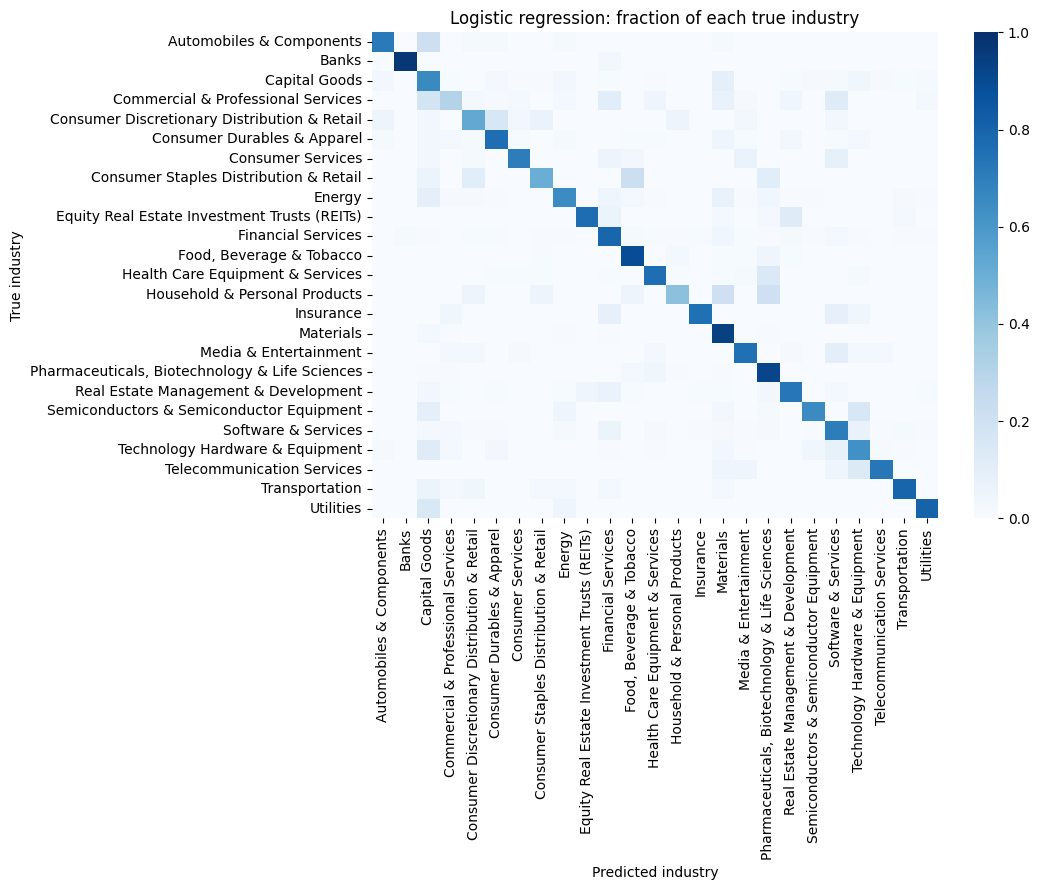

Capital Goods                       Materials                                         28
Technology Hardware & Equipment     Capital Goods                                     21
Materials                           Capital Goods                                     18
Commercial & Professional Services  Capital Goods                                     15
Health Care Equipment & Services    Pharmaceuticals, Biotechnology & Life Sciences    15
Name: Misclassifications, dtype: int64

k-NN | fitting size / error-rate correlation: -0.283


,precision,recall,f1-score,support
Commercial & Professional Services,0.612903,0.231707,0.336283,82.0
Consumer Staples Distribution & Retail,0.600000,0.333333,0.428571,18.0
Household & Personal Products,0.416667,0.526316,0.465116,19.0
Consumer Discretionary Distribution & Retail,0.574074,0.543860,0.558559,57.0
Capital Goods,0.619938,0.646104,0.632750,308.0
Semiconductors & Semiconductor Equipment,0.740741,0.634921,0.683761,63.0
Technology Hardware & Equipment,0.723926,0.666667,0.694118,177.0
Energy,0.809524,0.611511,0.696721,139.0
Software & Services,0.733766,0.676647,0.704050,167.0
Real Estate Management & Development,0.673267,0.739130,0.704663,92.0


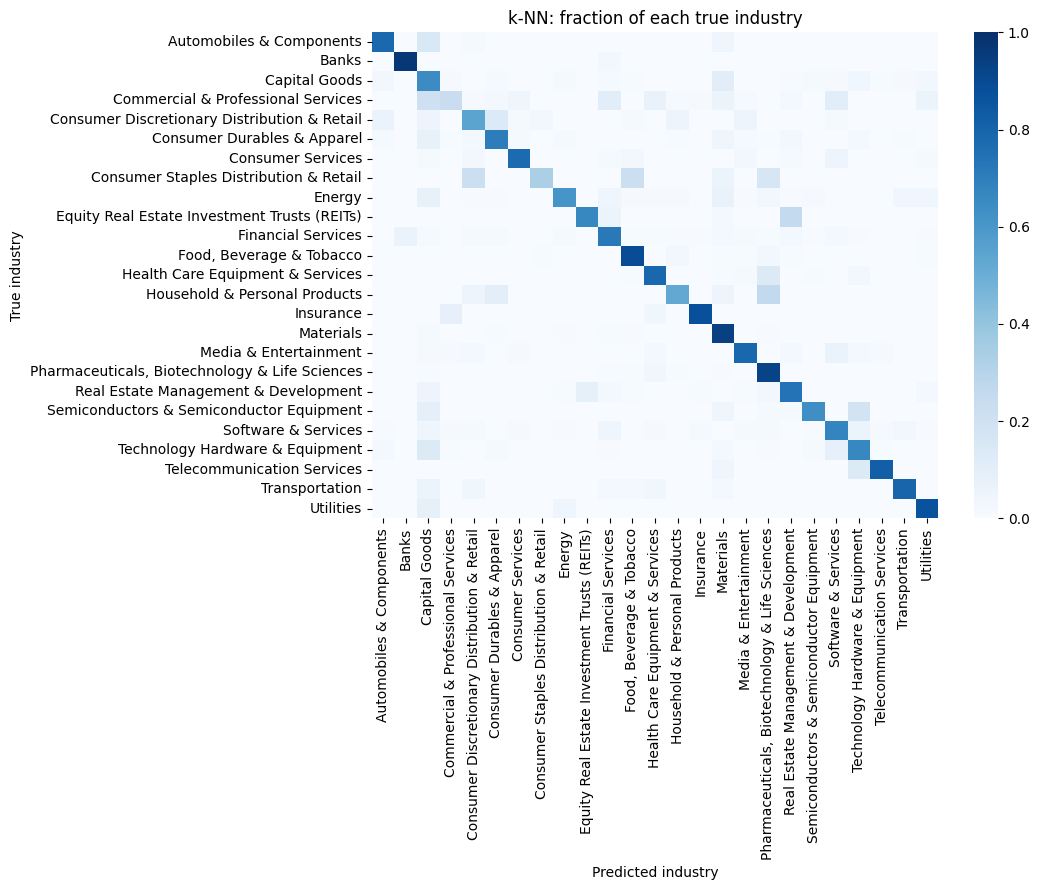

Capital Goods                       Materials              33
Technology Hardware & Equipment     Capital Goods          24
Commercial & Professional Services  Capital Goods          17
Materials                           Capital Goods          16
Technology Hardware & Equipment     Software & Services    15
Name: Misclassifications, dtype: int64

,Accuracy,Weighted F1,Macro F1
Model,,,
Logistic regression,0.781457,0.777788,0.717515
k-NN,0.777042,0.771401,0.710471


k-NN correct,False,True
LR correct,,
False,520,173
True,187,2291


In [7]:
rows = []  # [07.01] Collect the two models' summary metrics.
for name, prediction in predictions.items():  # [07.02] Analyze both classifiers with the same short loop.
    # [07.03] Calculate accuracy and weighted/macro F1 on the same records.
    rows.append([name, accuracy_score(y_val, prediction),
                 f1_score(y_val, prediction, average='weighted'),
                 f1_score(y_val, prediction, average='macro')])
    # [07.04] Get per-industry precision, recall, F1, and support.
    report = pd.DataFrame(classification_report(y_val, prediction,
        labels=np.arange(len(le.classes_)), target_names=le.classes_,
        output_dict=True, zero_division=0)).T.loc[le.classes_]
    # [07.05] Align industry names when relating fitting size to validation errors.
    print(name, '| fitting size / error-rate correlation:', round(counts.corr(1 - report['recall']), 3))
    display(report.sort_values('f1-score'))  # [07.06] Show the weakest industries first.
    # [07.07] Count true-industry rows against predicted-industry columns.
    cm = pd.DataFrame(confusion_matrix(y_val, prediction, labels=np.arange(len(le.classes_))),
                      index=le.classes_, columns=le.classes_)
    fig, ax = plt.subplots(figsize=(11, 9))  # [07.08] Create axes for this model's confusion heatmap.
    # [07.09] Normalize each true-industry row before coloring it.
    sns.heatmap(cm.div(cm.sum(axis=1), axis=0), cmap='Blues', vmin=0, vmax=1, ax=ax)
    # [07.10] Label the true and predicted axes explicitly.
    ax.set(xlabel='Predicted industry', ylabel='True industry', title=name + ': fraction of each true industry')
    fig.tight_layout()  # [07.11] Keep the long industry labels visible.
    plt.show()  # [07.12] Display the confusion heatmap.
    np.fill_diagonal(cm.values, 0)  # [07.13] Exclude correct counts from the error-pair ranking.
    # [07.14] Show the five largest off-diagonal confusion counts.
    display(cm.stack().nlargest(5).rename('Misclassifications'))
# [07.15] Build the direct classifier comparison table.
comparison = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Weighted F1', 'Macro F1']).set_index('Model')
display(comparison)  # [07.16] Display the comparison.
# [07.17] Count records where the models are correct or wrong together.
display(pd.crosstab(predictions['Logistic regression'] == y_val, predictions['k-NN'] == y_val,
                    rownames=['LR correct'], colnames=['k-NN correct']))

Logistic regression is the stronger required classifier: accuracy 78.15% and weighted F1 77.78%, versus 77.70% and 77.14% for k-NN. Macro F1 is lower (71.75% and 71.05%), exposing weaker small-industry performance. LR F1 is 97.17% for Banks and 92.43% for Materials, but 37.59% for Commercial & Professional Services. Both models often confuse Capital Goods with Materials (28 and 33 cases) and Technology Hardware & Equipment with Capital Goods (21 and 24). The size/error correlations are -0.362 and -0.283: larger fitting classes tend to have fewer errors, but the association is not a causal explanation. Both models fail on 520 records; 173 errors are unique to LR and 187 to k-NN. Their errors therefore overlap substantially.

## Optional: Confidence Weighted Prediction — official score

The course score is weighted F1 × (1 − Brier), with Brier = mean((confidence − correctness)²).
Confidence does not weight the F1 calculation. The function below keeps the supplied formula and checks.

In [8]:
def confidence_score(y_true, y_pred, confidence):  # [08.01] Keep the course's confidence-score interface and formula.
    """Official weighted F1 multiplied by one minus correctness Brier."""
    y_true = np.asarray(y_true)  # [08.02] Allow true labels to be supplied as a list or array.
    y_pred = np.asarray(y_pred)  # [08.03] Allow predicted labels to be supplied as a list or array.
    confidence = np.asarray(confidence, dtype=float)  # [08.04] Use numerical floating-point confidence values.
    # [08.05] Require one prediction and confidence for every target.
    assert len(y_true) == len(y_pred) == len(confidence), 'Inputs must have the same length'
    # [08.06] Require every confidence to lie between zero and one.
    assert np.all((confidence >= 0) & (confidence <= 1)), 'Confidence must be between 0 and 1'
    # [08.07] Calculate class-support-weighted F1; confidence is not a weight.
    f1 = f1_score(y_true, y_pred, average='weighted')
    correct = (y_true == y_pred).astype(float)  # [08.08] Represent a correct prediction as one and an error as zero.
    brier = np.mean((confidence - correct) ** 2)  # [08.09] Average the squared errors of the correctness confidence.
    return f1 * (1 - brier)  # [08.10] Apply exactly the official multiplicative score.

## Financial distributions

Financial reference data contain one row per fitting company. Boxplots show the centre and spread;
hiding outlier dots does not delete observations. Symmetric logarithmic axes retain negative values.

net_profit_margin            \
                                                           count    median   
industry                                                                     
Automobiles & Components                                     475  0.034077   
Banks                                                        710  0.245811   
Capital Goods                                               2276  0.039592   
Commercial & Professional Services                           532  0.033262   
Consumer Discretionary Distribution & Retail                 473  0.017686   
Consumer Durables & Apparel                                  832  0.031132   
Consumer Services                                            469  0.028669   
Consumer Staples Distribution & Retail                       140  0.022693   
Energy                                                       795  0.043417   
Equity Real Estate Investment Trusts (REITs)                 323  0.252600   
Financial Services                                          1115  0.259259   
Food, Beverage & Tobacco                                     782  0.038511   
Health Care Equipment & Services                             678 -0.003701   
Household & Personal Products                                161  0.035555   
Insurance                                                    211  0.079118   
Materials                                                   5438  0.049562   
Media & Entertainment                                        620 -0.021711   
Pharmaceuticals, Biotechnology & Life Sciences              1074 -0.188698   
Real Estate Management & Development                         636  0.080751   
Semiconductors & Semiconductor Equipment                     457  0.042345   
Software & Services                                         1012  0.002503   
Technology Hardware & Equipment                             1143  0.025251   
Telecommunication Services                                   154  0.033975   
Transportation                                               434  0.070571   
Utilities                                                    414  0.085487   

                                               ebitda_margin            \
                                                       count    median   
industry                                                                 
Automobiles & Components                                 133  0.092523   
Banks                                                    209  0.256049   
Capital Goods                                            727  0.106101   
Commercial & Professional Services                       290  0.097789   
Consumer Discretionary Distribution & Retail             277  0.071807   
Consumer Durables & Apparel                              272  0.090690   
Consumer Services                                        260  0.147591   
Consumer Staples Distribution & Retail                    66  0.050672   
Energy                                                   338  0.165206   
Equity Real Estate Investment Trusts (REITs)             221  0.580373   
Financial Services                                       639  0.355395   
Food, Beverage & Tobacco                                 310  0.091367   
Health Care Equipment & Services                         411  0.004134   
Household & Personal Products                             78  0.105431   
Insurance                                                121  0.129391   
Materials                                                732  0.076083   
Media & Entertainment                                    324  0.040945   
Pharmaceuticals, Biotechnology & Life Sciences           572 -0.958235   
Real Estate Management & Development                     253  0.221348   
Semiconductors & Semiconductor Equipment                 102  0.035120   
Software & Services                                      543  0.016398   
Technology Hardware & Equipment                          308  0.044118   
Telecommunic

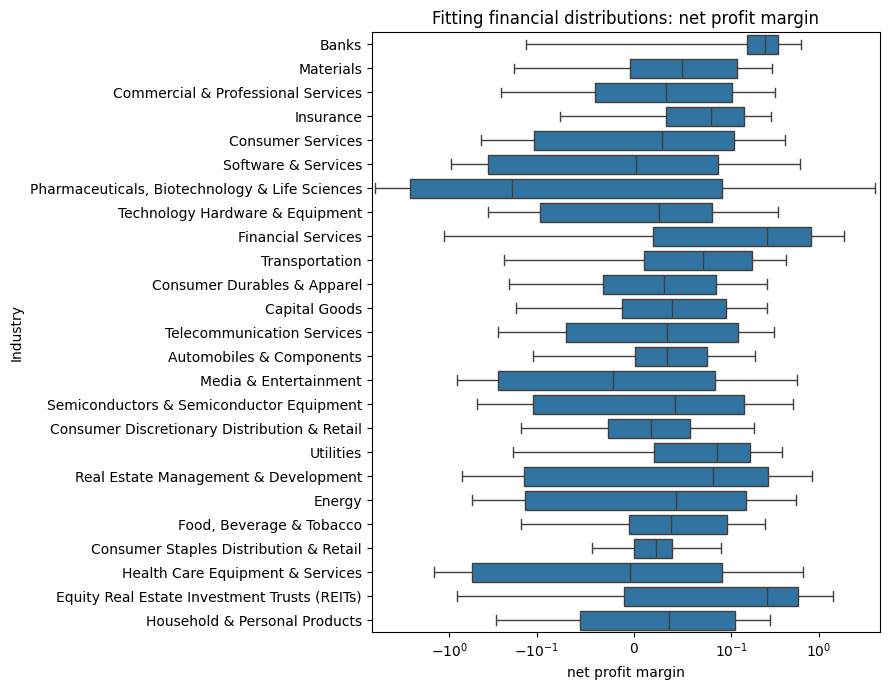

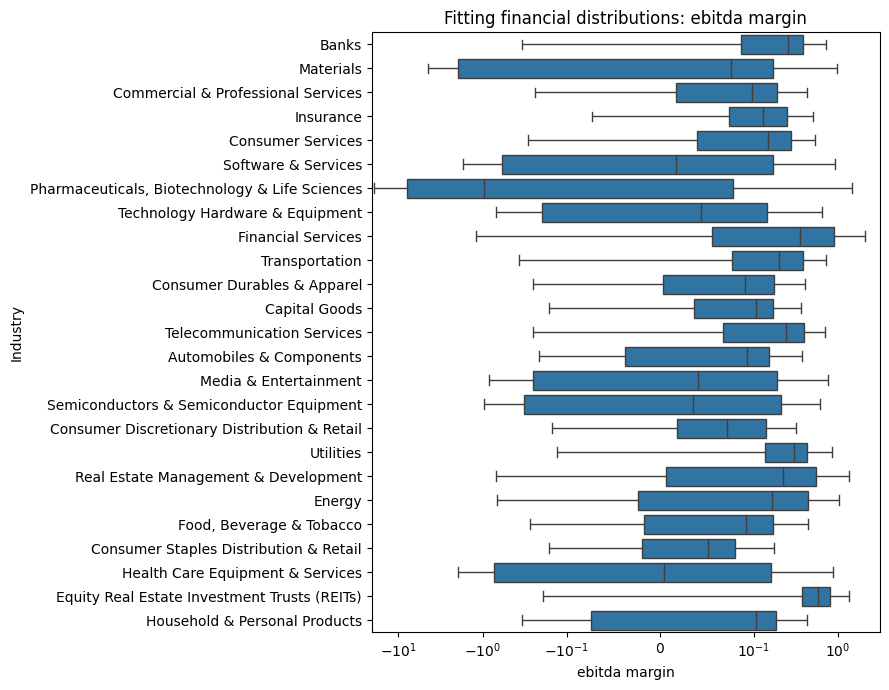

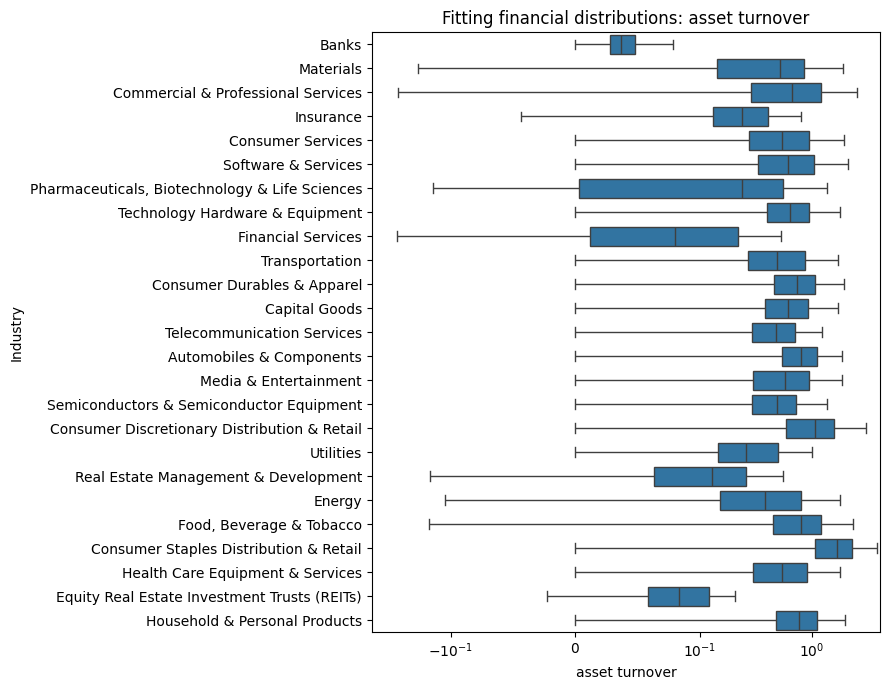

In [9]:
profile_data = df_fit.drop_duplicates('id')  # [09.01] Give each fitting company one vote in the financial references.
# [09.02] Show observation counts and medians for every industry and ratio.
display(profile_data.groupby('industry')[ratios].agg(['count', 'median']))
for column in ratios:  # [09.03] Inspect all three ratios with the same plotting code.
    fig, ax = plt.subplots(figsize=(9, 7))  # [09.04] Create readable axes for this ratio.
    # [09.05] Show quartiles and medians; hide dots rather than delete outliers.
    sns.boxplot(data=profile_data, x=column, y='industry', showfliers=False, ax=ax)
    ax.set_xscale('symlog', linthresh=0.1)  # [09.06] Keep negative values while displaying large magnitudes.
    # [09.07] Label the financial ratio, industry, and plot title.
    ax.set(xlabel=column.replace('_', ' '), ylabel='Industry',
           title='Fitting financial distributions: ' + column.replace('_', ' '))
    fig.tight_layout()  # [09.08] Prevent labels from being clipped.
    plt.show()  # [09.09] Display this financial distribution.

The ratio distributions overlap broadly. Pharmaceutical net margins include substantial losses; Banks and REITs have much lower typical asset turnover than Consumer Staples Distribution & Retail. EBITDA margin is missing in 19,279 of 29,561 raw financial records (65.2%), before removing infinities. Financial evidence is incomplete and cannot determine industry on its own.

## Text votes and financial compatibility

Soft voting combines aligned classifier probabilities. For each predicted industry, financial percentiles
give bounded compatibility: 2 × min(percentile, 1 − percentile). Ties use middle ranks.
This is supporting evidence, not a correctness probability or a formal p-value.
Absent ratios contribute no evidence; all-missing compatibility is 0.5 with availability 0.

In [10]:
profiles = {}  # [10.01] Store the fitting-only financial reference samples.
for industry, group in profile_data.groupby('industry'):  # [10.02] Separate the unique fitting companies by known industry.
    for column in ratios:  # [10.03] Create one reference for each of the three ratios.
        # [10.04] Sort available values so percentile lookups are quick.
        profiles[industry, column] = np.sort(group[column].dropna().to_numpy())

def confidence_features(companies, proba_lr, proba_knn):  # [10.05] Reuse exactly one confidence-feature calculation.
    # [10.06] Combine aligned industry probabilities with the tuning-selected weight.
    votes = weight * proba_lr + (1 - weight) * proba_knn
    prediction = votes.argmax(1)  # [10.07] Choose each row's largest ensemble vote.
    top = np.sort(votes, axis=1)  # [10.08] Sort each vote vector to find its largest two entries.
    agreement = proba_lr.argmax(1) == proba_knn.argmax(1)  # [10.09] Record whether LR and k-NN choose the same industry.
    names = le.inverse_transform(prediction)  # [10.10] Find the industry names predicted by the ensemble.
    # [10.11] Add absent financial columns as missing rather than inventing values.
    financial = companies.reindex(columns=ratios)
    # [10.12] Start each company's compatibility total and evidence count at zero.
    total, available = np.zeros(len(companies)), np.zeros(len(companies))
    for (industry, column), reference in profiles.items():  # [10.13] Visit each industry-ratio reference once.
        values = financial[column].to_numpy()  # [10.14] Read this ratio in the input-row order.
        # [10.15] Use finite values for the predicted industry, never the true industry.
        mask = (names == industry) & np.isfinite(values)
        # [10.16] Count reference values strictly below the observation.
        left = np.searchsorted(reference, values[mask], side='left')
        # [10.17] Count reference values below or equal to the observation.
        right = np.searchsorted(reference, values[mask], side='right')
        # [10.18] Use the midpoint of the two empirical cumulative fractions.
        percentile = (left + right) / (2 * len(reference))
        # [10.19] Add a bounded middle-versus-tail compatibility score.
        total[mask] += 2 * np.minimum(percentile, 1 - percentile)
        available[mask] += 1  # [10.20] Count this observed financial contribution.
    # [10.21] Average available scores; distinguish no evidence with availability zero.
    compatibility = np.divide(total, available, out=np.full(len(companies), 0.5), where=available > 0)
    # [10.22] Return the class codes and five confidence inputs in a fixed order.
    return prediction, np.column_stack([top[:, -1], top[:, -1] - top[:, -2],
                                        agreement, compatibility, available / len(ratios)])

## Learning confidence

The text calibrator uses the largest vote, the gap to second place, and model agreement.
The financial calibrator also uses compatibility and availability. Both learn correctness on calibration
companies only; they do not change the predicted industry. The financial version is the inference model.

In [11]:
# [11.01] Build confidence inputs from held-out calibration companies.
pred_cal, features_cal = confidence_features(df_cal, lr_cal, knn_cal)
correct_cal = (pred_cal == y_cal).astype(int)  # [11.02] Set the binary learning target to whether the ensemble was correct.
# [11.03] Fit the text-only confidence comparison using the first three inputs.
text_calibrator = LogisticRegression().fit(features_cal[:, :3], correct_cal)
# [11.04] Fit correctness confidence with the two additional financial inputs.
finance_calibrator = LogisticRegression().fit(features_cal, correct_cal)
# [11.05] Build the same inputs for validation without fitting anything.
pred_val, features_val = confidence_features(df_val, lr_val, knn_val)

## Evaluating confidence



In [12]:
confidences = {  # [12.01] Compare raw votes, text confidence, and financial confidence.
    'Raw ensemble': features_val[:, 0],
    'Text calibration': text_calibrator.predict_proba(features_val[:, :3])[:, 1],
    'Financial calibration': finance_calibrator.predict_proba(features_val)[:, 1]
}
rows = []  # [12.02] Collect all three approaches using the same predictions.
for name, confidence in confidences.items():  # [12.03] Evaluate each confidence vector without changing its labels.
    # [12.04] Calculate weighted F1, correctness Brier, and the official score.
    rows.append([name, f1_score(y_val, pred_val, average='weighted'),
                 np.mean((confidence - (pred_val == y_val)) ** 2),
                 confidence_score(y_val, pred_val, confidence)])
# [12.05] Give the confidence comparison clear column names.
bonus = pd.DataFrame(rows, columns=['Method', 'Weighted F1', 'Brier', 'Official score']).set_index('Method')
display(bonus)  # [12.06] Display the complete confidence comparison, including weaker results.

,Weighted F1,Brier,Official score
Method,,,
Raw ensemble,0.780881,0.137380,0.673604
Text calibration,0.780881,0.135923,0.674742
Financial calibration,0.780881,0.135582,0.675008


The ensemble reaches 78.09% weighted F1 and 78.62% accuracy. Calibration leaves those labels unchanged. Financial calibration gives Brier 0.13558 and official score 67.50%, compared with 67.36% for raw confidence and 67.47% for text calibration. The additional financial gain is only about 0.03 percentage points on this split; a strong general benefit is not established.

## Confidence and human review

A fixed confidence threshold of 0.8 flags cases for human review. It is a starting policy, not an
optimized or instructor-mandated cutoff. Flagged records keep their predictions and remain in every score.

,Count,Mean_confidence,Accuracy
Bin,,,
"(0.2, 0.3]",11,0.280684,0.363636
"(0.3, 0.4]",128,0.364389,0.437500
"(0.4, 0.5]",258,0.449622,0.449612
"(0.5, 0.6]",235,0.548430,0.557447
"(0.6, 0.7]",237,0.649346,0.628692
"(0.7, 0.8]",300,0.752411,0.723333
"(0.8, 0.9]",617,0.857862,0.820097
"(0.9, 1.0]",1385,0.937454,0.948736


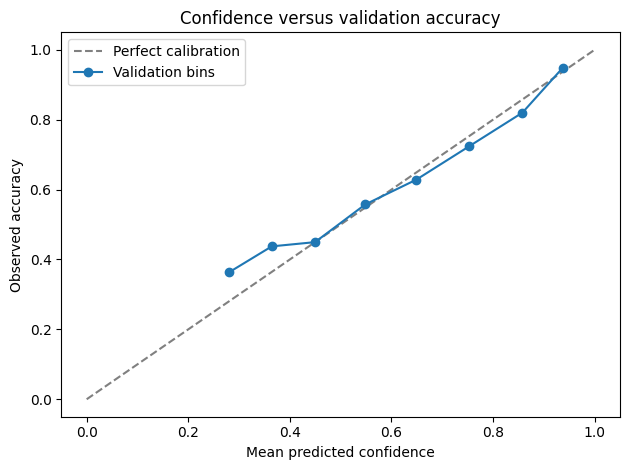

,Count,Accuracy
False,2002,0.909091
True,1169,0.575706


Review fraction: 0.3686534216335541 | errors captured: 496 of 678


In [13]:
# [13.01] Use the financial-calibrated confidence for inference and review.
confidence_val = confidences['Financial calibration']
# [13.02] Pair confidence with observed correctness for evaluation only.
outcomes = pd.DataFrame({'Confidence': confidence_val, 'Correct': pred_val == y_val})
# [13.03] Divide zero to one into ten confidence intervals.
outcomes['Bin'] = pd.cut(confidence_val, np.linspace(0, 1, 11), include_lowest=True)
# [13.04] Compare mean confidence, actual accuracy, and sample size in each bin.
reliability = outcomes.groupby('Bin', observed=True).agg(
    Count=('Correct', 'size'), Mean_confidence=('Confidence', 'mean'), Accuracy=('Correct', 'mean'))
display(reliability)  # [13.05] Show counts so small confidence bins are not overinterpreted.
fig, ax = plt.subplots()  # [13.06] Create the confidence-versus-accuracy plot.
# [13.07] Draw the ideal calibration line, where confidence equals accuracy.
ax.plot([0, 1], [0, 1], '--', color='gray', label='Perfect calibration')
# [13.08] Plot the observed validation-bin values.
ax.plot(reliability.Mean_confidence, reliability.Accuracy, 'o-', label='Validation bins')
# [13.09] Label the calibration axes and title.
ax.set(xlabel='Mean predicted confidence', ylabel='Observed accuracy', title='Confidence versus validation accuracy')
ax.legend()  # [13.10] Identify the observed and ideal lines.
fig.tight_layout()  # [13.11] Fit the plot labels within the figure.
plt.show()  # [13.12] Display the calibration plot.
review = confidence_val < 0.8  # [13.13] Flag confidence strictly below the fixed 0.8 review threshold.
# [13.14] Compare flagged and unflagged records; True means human review.
display(outcomes.groupby(review).agg(Count=('Correct', 'size'), Accuracy=('Correct', 'mean')))
# [13.15] Show review workload and the number of errors the flags capture.
print('Review fraction:', review.mean(), '| errors captured:',
      np.sum(review & (pred_val != y_val)), 'of', np.sum(pred_val != y_val))

Review flags cover 1,169 of 3,171 records (36.9%) and capture 496 of 678 errors (73.2%). Flagged accuracy is 57.57%; unflagged accuracy is 90.91%. Small confidence bins are noisy, and the 0.8–0.9 bin remains somewhat overconfident. Selective high-confidence accuracy is not the official score.

## Predicting new companies and checking repeated representations

`predict_industry(companies)` returns industry names and confidence as two vectors in input-row order.
It reads no true industry labels. Inputs need the embedding column; financial ratios are optional.
If separate financial records are supplied, aggregate and join them by ID as in the loading cell.

In [14]:
def predict_industry(companies):  # [14.01] Expose the required label-vector and confidence-vector prediction interface.
    X = embeddings(companies)  # [14.02] Convert new descriptions with the same embedding parser.
    # [14.03] Reuse both classifiers, fitting PCA, and the confidence features.
    prediction, features = confidence_features(companies, lr.predict_proba(X), knn.predict_proba(pca.transform(X)))
    # [14.04] Return industry names and correctness confidence in input-row order.
    return le.inverse_transform(prediction), finance_calibrator.predict_proba(features)[:, 1]

example = df_val.drop(columns='industry').head(3)  # [14.05] Demonstrate prediction after removing the true industry column.
labels, confidence = predict_industry(example)  # [14.06] Call the same public prediction function used for new companies.
# [14.07] Display three real examples with their IDs and predicted outputs.
display(pd.DataFrame({'ID': example.id.to_numpy(), 'Predicted industry': labels, 'Confidence': confidence}))
# [14.08] Check exact stored embedding strings shared with fitting records.
seen = df_val.business_description_embedding.isin(df_fit.business_description_embedding)
# [14.09] Compare accuracy on seen and unseen stored representations.
display(pd.DataFrame({'Embedding seen in fitting': seen.to_numpy(), 'Correct': pred_val == y_val})
        .groupby('Embedding seen in fitting').agg(Count=('Correct', 'size'), Accuracy=('Correct', 'mean')))
# [14.10] Report elapsed notebook time through the final code cell.
print('Whole notebook seconds:', round(perf_counter() - started, 1))

,ID,Predicted industry,Confidence
0,21057,Capital Goods,0.710744
1,24720,Materials,0.950159
2,24392,Consumer Services,0.909014


,Count,Accuracy
Embedding seen in fitting,,
False,2716,0.751473
True,455,0.993407


Whole notebook seconds: 208.6


Company IDs are disjoint, but 455 validation records (14.35%) share an exact stored embedding string with fitting records. Accuracy is 99.34% on those and 75.15% on unseen stored representations. This evaluates unseen IDs, not wholly unseen representations. The local 85% score target was not reached; confidence alone cannot exceed the current 78.09% weighted-F1 ceiling. The private-test score and the 45-minute Intel Mac limit remain unverified. This cloud run took 221.1 seconds including checks, with a runner-plus-kernel peak-memory upper bound of 1.37 GiB. The same holdout has been examined in earlier versions; these are revised holdout results, not a new independent test. AI assistance was used to develop and review the code and explanatory material.